# HW6: Running a Big Data Bowl Submission on the HPC

**Course:** SPOA 5010 

## Submission Description

**Submission:** *(Under)cover-2: Predicting Disguised Defenses*, Sarah Pollack, NFL Big Data Bowl 2025 ([Kaggle notebook](https://www.kaggle.com/code/sarahpollack/under-cover-2-predicting-disguised-defenses), [GitHub code](https://github.com/sepollack/nfl-bdb-25))  

Pollack's project asks whether a defense disguises its coverage before the snap, for example by showing two high safeties and then rotating to a single-high look. 

The code is three R scripts that run in order in one R session:

1. **`data_cat.R`**: keeps dropback passes and labels each play disguised or undisguised.
2. **`model_cr.R`**: the coverage reader, a convolutional neural network that predicts 1 vs. 2 high safeties. It's trained only on undisguised plays, so it learns what an honest setup is.
3. **`model_ds.R`**: the Disguise Score model, a second CNN with the same architecture that predicts whether a play is disguised. This is evaluated on 1,000 held-out plays.

## Setting It Up on the HPC

**Getting the code and data in place**
- Cloned Pollack's GitHub repo and copied it to my home directory on the HPC with `scp`.

**Installing R packages** 
- Loaded R with `module load R/4.5.1`.
- Installed `tidyverse`, `hms`, `splitTools`, `glue`, `pROC`, `probably` and `scales`, plus `torch` from the prebuilt CPU build at `torch-cdn.mlverse.org`.

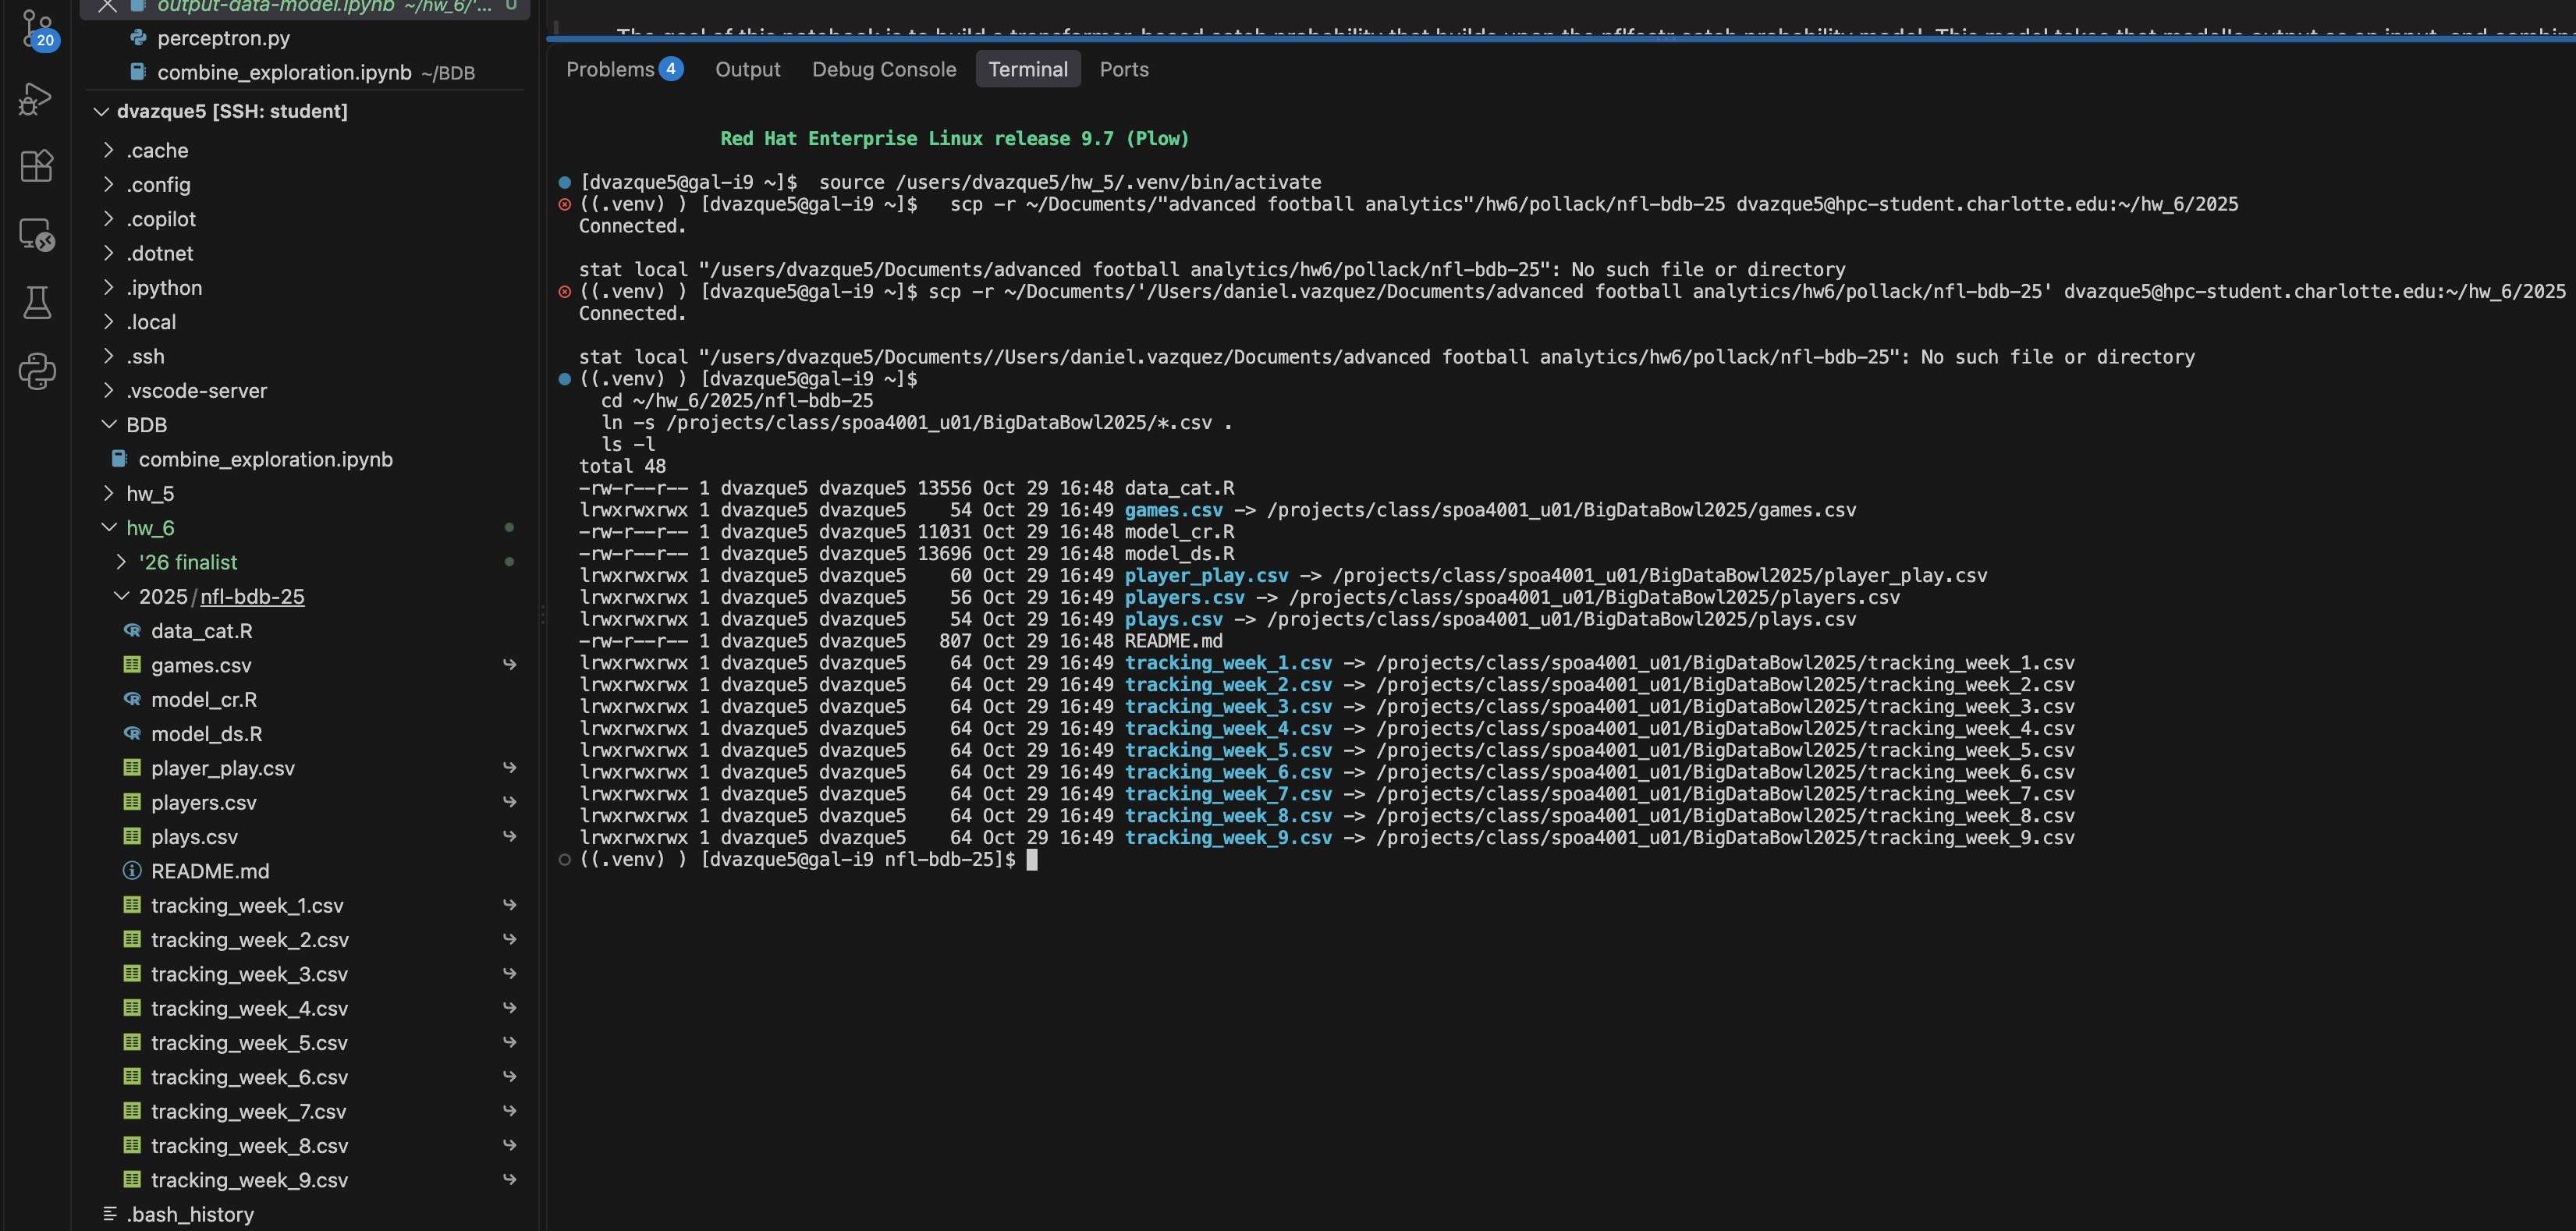

## Q1: Running the Model


**Job submitted** (job 23916, waiting in the Centaurus queue)

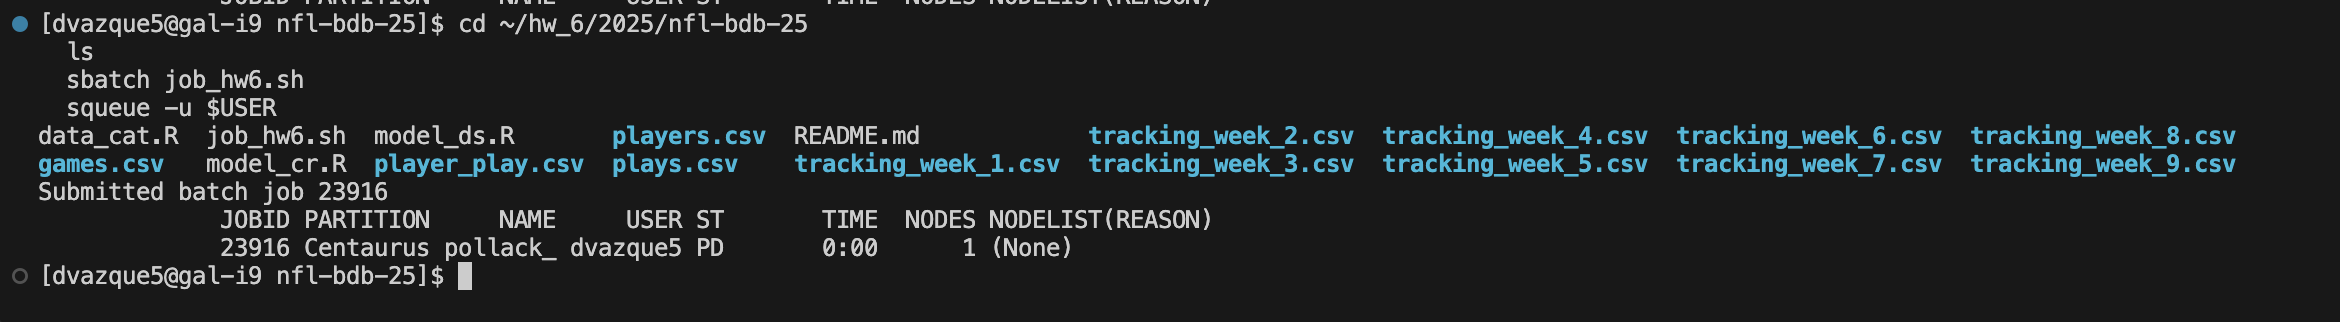

**Training in progress** (fold-by-fold output)

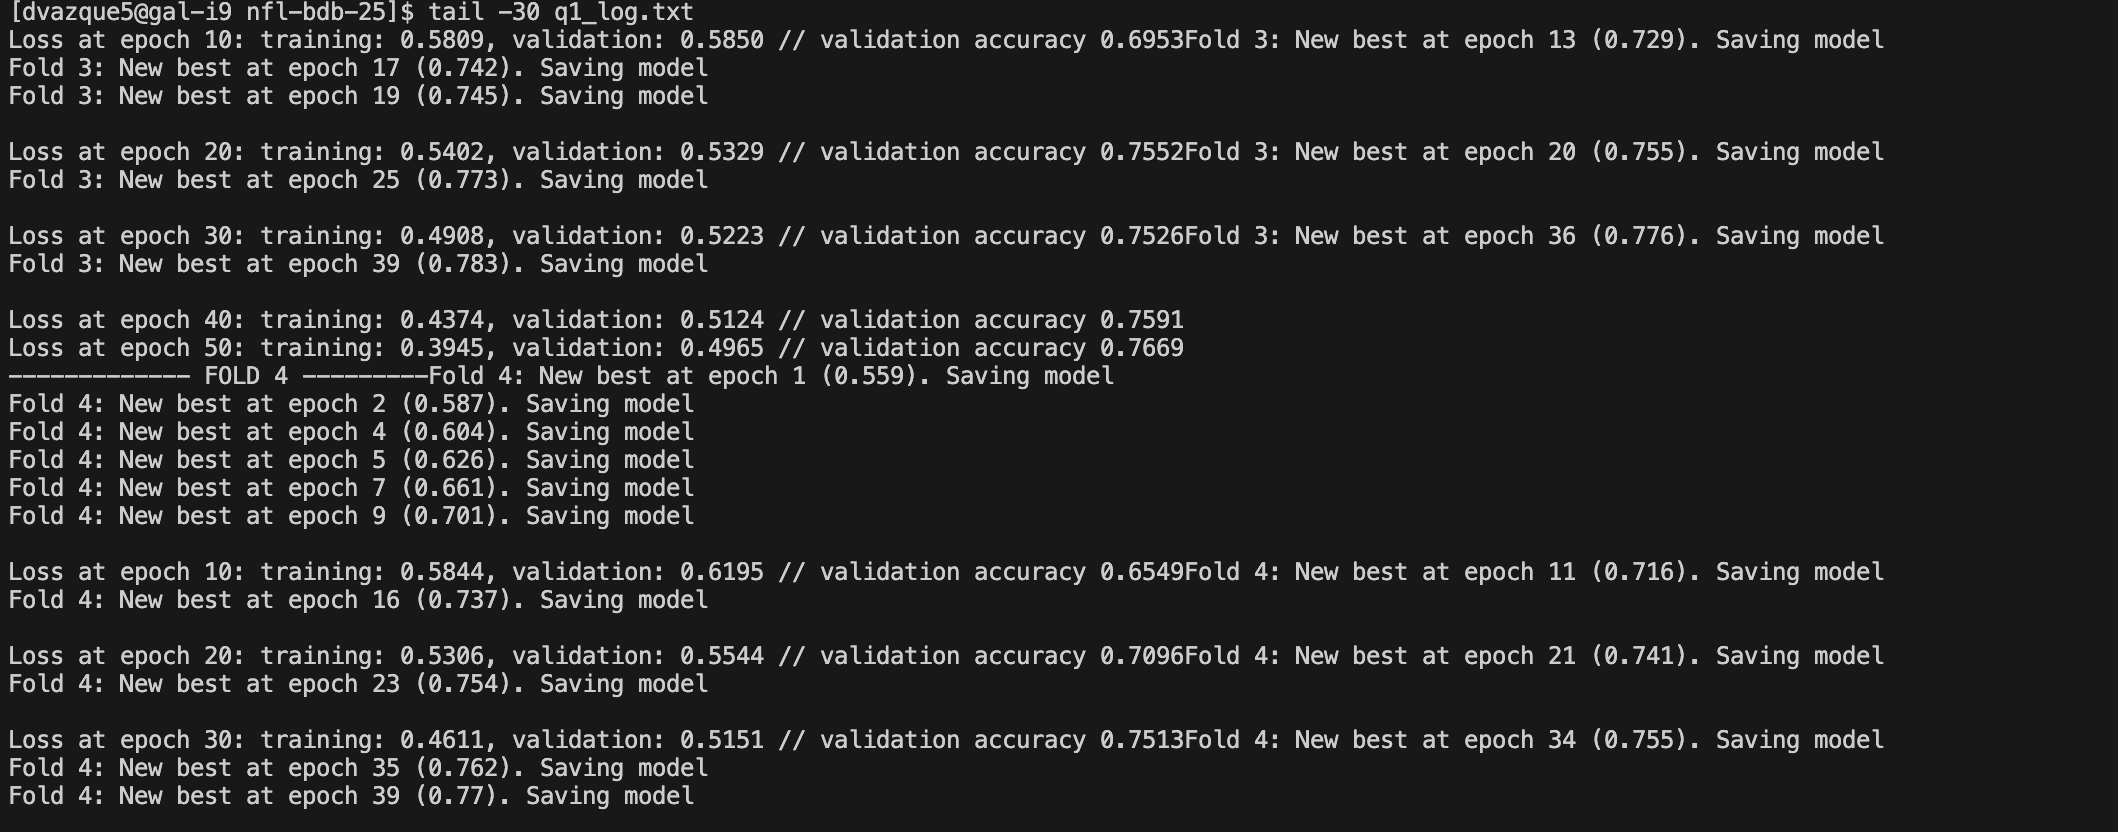

**Job finished** 

```
Started: Thu Oct 29 06:13:30 PM EDT 2026 on gal-c1.charlotte.edu
Finished: Thu Oct 29 06:47:32 PM EDT 2026
```

**Results and resource usage** 

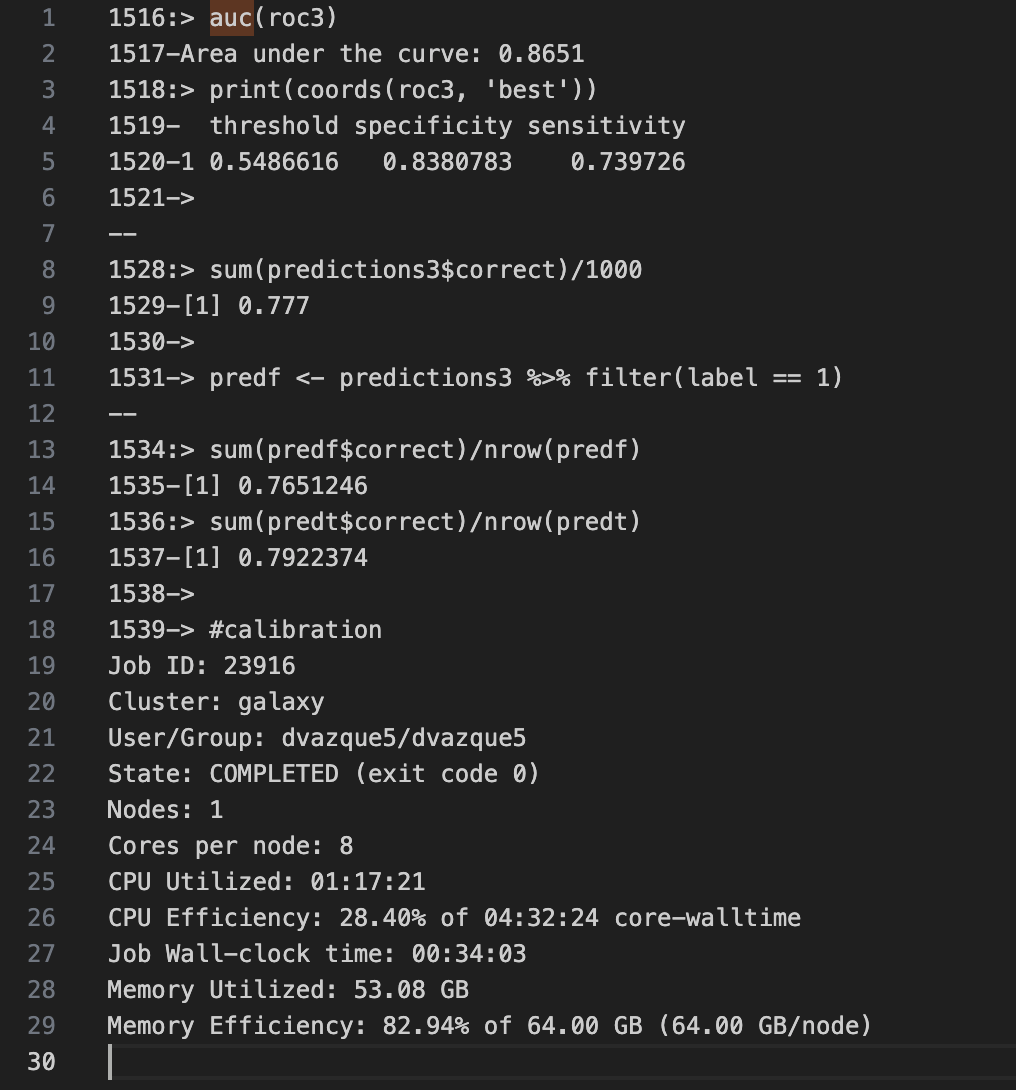

### Q1 Results

**Coverage reader** (1 vs. 2 high safeties)

| Plays | Accuracy |
|---|---|
| Undisguised plays | **93.4%** |
| Disguised plays | **21.1%** |

The coverage reader is very accurate when the defense shows what it plays, and it's fooled about 79% of the time when the defense disguises.

**Disguise Score model**

| Metric | Value |
|---|---|
| AUC | 0.865 |
| Overall accuracy | 77.7% |
| Accuracy on undisguised plays | 76.5% |
| Accuracy on disguised plays | 79.2% |
| Best cutoff (sensitivity / specificity) | 0.549 (0.740 / 0.838) |
| Best validation accuracy, by fold | 0.779, 0.767, 0.783, 0.771, 0.730 |

| ROC curve | Calibration |
|---|---|
| 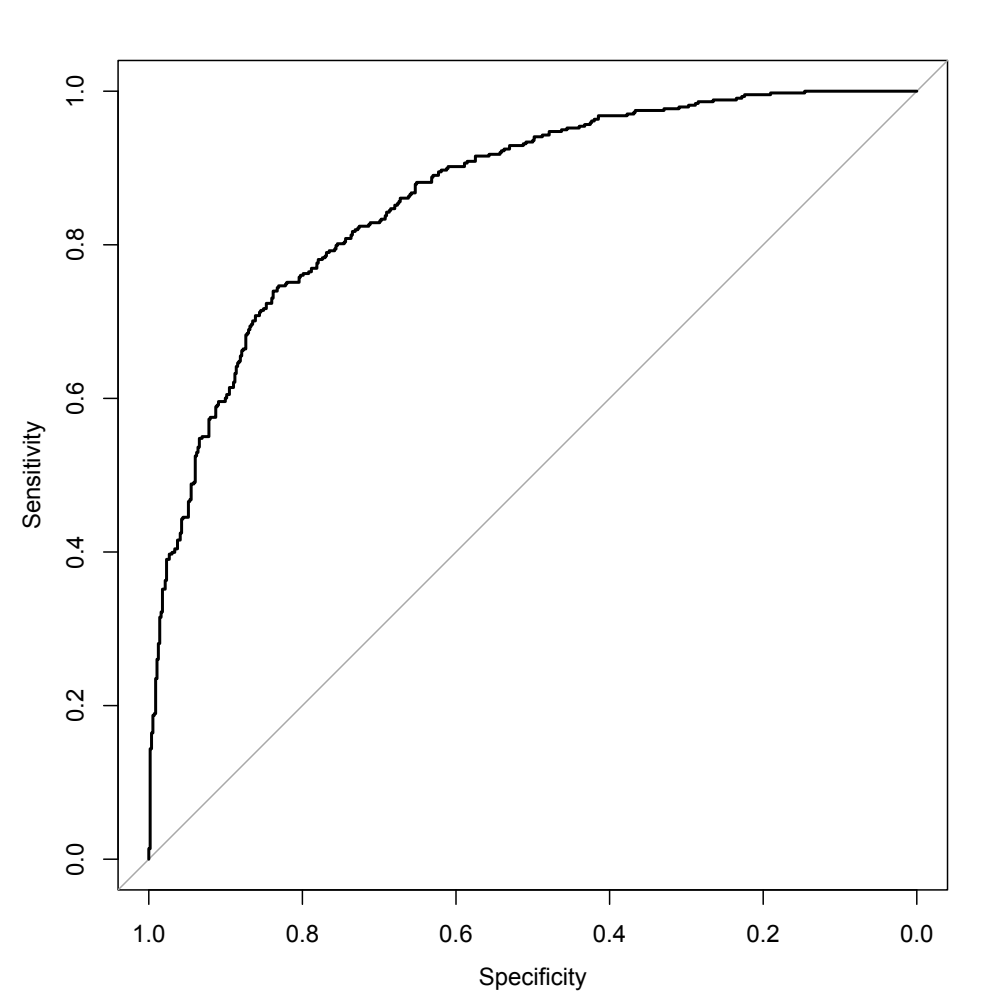 | 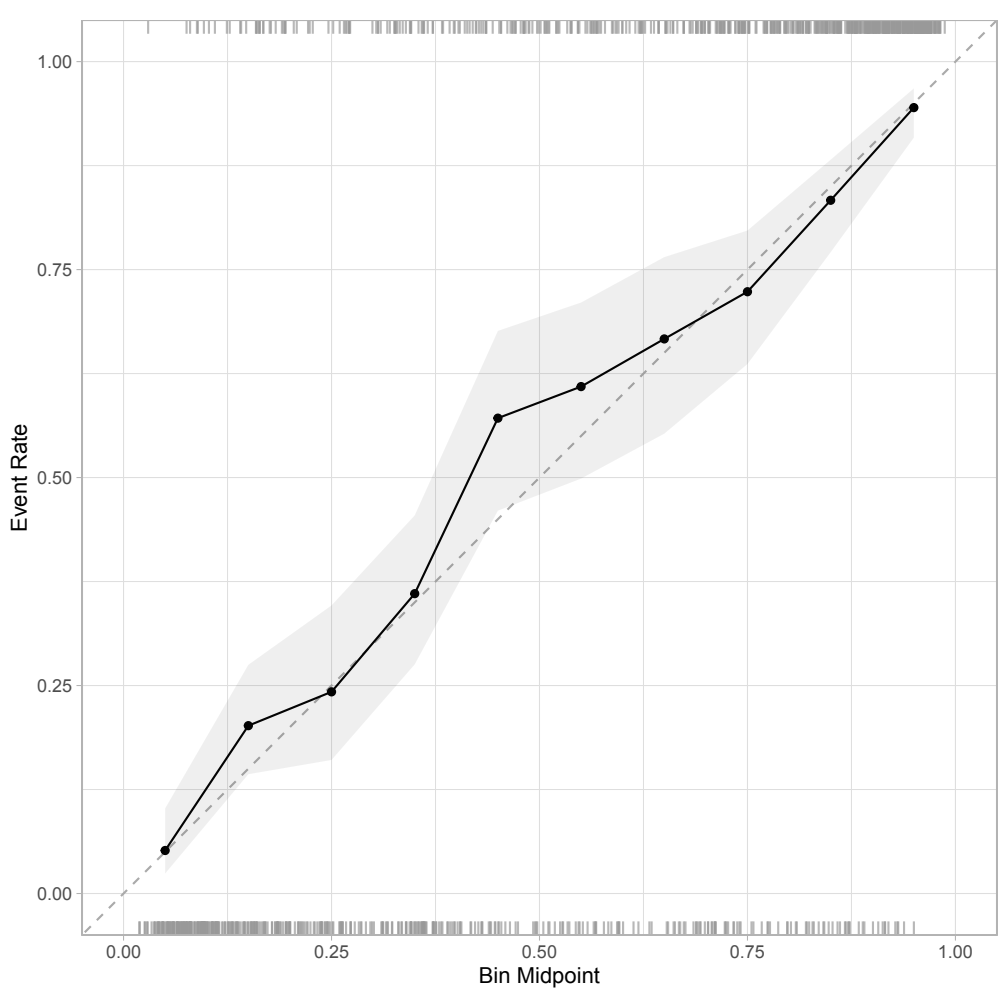 |

- The ROC curve curves well above the diagonal (AUC 0.865), so the model separates disguised from undisguised plays well.
- The calibration plot stays close to the diagonal. When the model gives a probability around 70%, the event happens about 70% of the time, so its probabilities can be read at face value.

### Q1 Training Log

**Disguise Score model** (training loss / validation loss, printed every 10 epochs)

| Epoch | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|
| 10 | 0.579 / 0.562 | 0.574 / 0.610 | 0.581 / 0.585 | 0.584 / 0.620 | 0.560 / 0.590 |
| 20 | 0.516 / 0.536 | 0.530 / 0.553 | 0.540 / 0.533 | 0.531 / 0.554 | 0.512 / 0.575 |
| 30 | 0.460 / 0.514 | 0.457 / 0.527 | 0.491 / 0.522 | 0.461 / 0.515 | 0.444 / 0.576 |
| 40 | 0.410 / 0.501 | 0.407 / 0.527 | 0.437 / 0.512 | 0.392 / 0.525 | 0.386 / 0.579 |
| 50 | 0.348 / 0.551 | 0.339 / 0.547 | 0.395 / 0.497 | 0.334 / 0.509 | 0.322 / 0.633 |

Training loss keeps falling through epoch 50 in every fold, but validation loss levels off around epoch 30 and rises between epochs 40 and 50 in folds 1, 2 and 5. By epoch 50 the gap between training and validation loss averages 0.200. This is mild overfitting: the model starts memorizing the training plays instead of learning patterns that carry over.

### Q1 Mean Disguise Score by Coverage Type

| Coverage | Disguised plays | Undisguised plays | Difference (pts) |
|---|---|---|---|
| Cover-1 | 76.4% | 20.7% | 55.7 |
| Cover-3 | 70.5% | 21.8% | 48.7 |
| 2-Man | 65.0% | 29.5% | 35.5 |
| Quarters | 67.5% | 38.0% | 29.6 |
| Cover-6 | 62.2% | 35.1% | 27.1 |
| Cover-2 | 58.8% | 35.8% | 23.0 |
| Cover-0 | 79.4% | – | – |

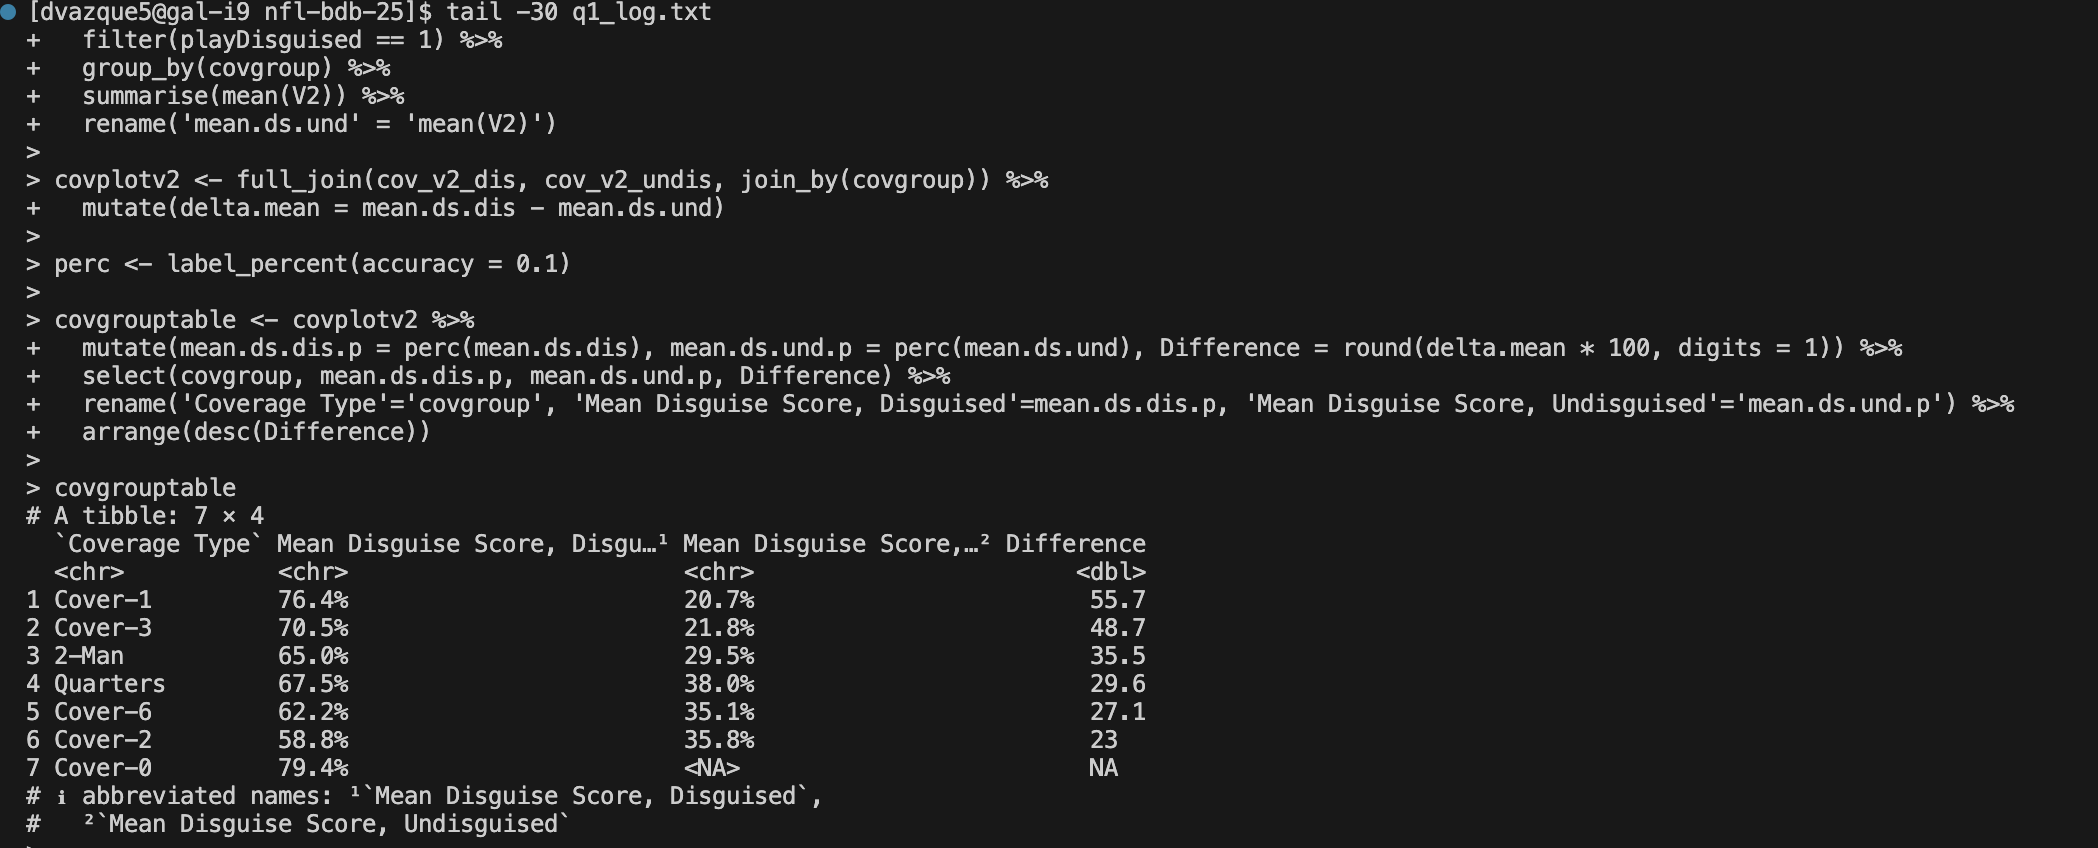

The model separates disguised from undisguised plays best in single-high coverages (Cover-1, Cover-3) and worst in two-high coverages (Cover-2, Cover-6). 

## Q2: Changing One Parameter

**Parameter changed:** dropout in the Disguise Score model, from **0.3 to 0.5** (`model_ds.R`, line 187). The coverage reader (`model_cr.R`) was left at 0.3.

```r
nn_dropout(p = 0.5)   # was nn_dropout(p = 0.3)
```

Dropout randomly switches off a share of the network's neurons on each training step, so the model can't lean too hard on any one feature. A higher dropout is a stronger guard against overfitting. I picked it because the Q1 training log showed the Disguise Score model overfitting (see the training log table in Q1).

**Job submitted** (job 23919, same settings as Q1 through `job_q2.sh`)

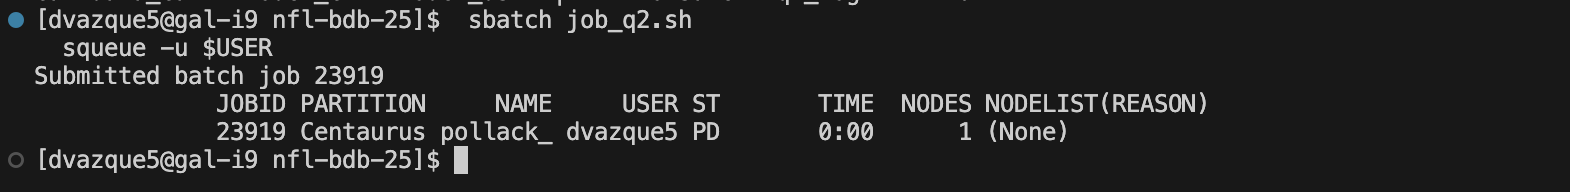

**Job finished**

```
Started: Thu Oct 29 09:05:27 PM EDT 2026 on gal-c1.charlotte.edu
Finished: Thu Oct 29 09:38:26 PM EDT 2026
```

**Both jobs completed, and the dropout change on the HPC** (0.5 in `model_ds.R`, 0.3 in `model_cr.R`)

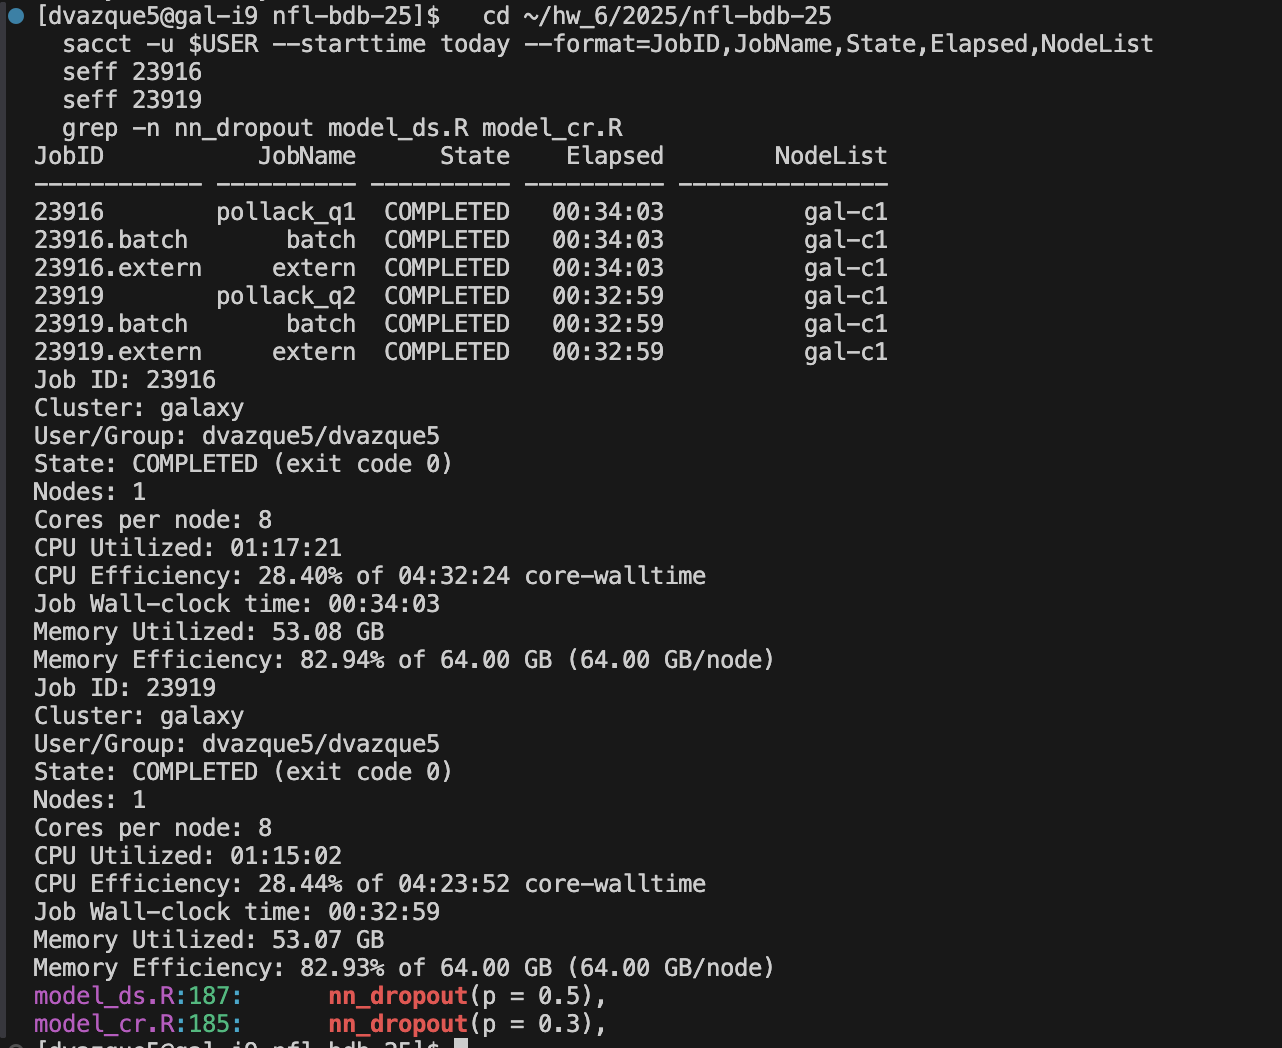

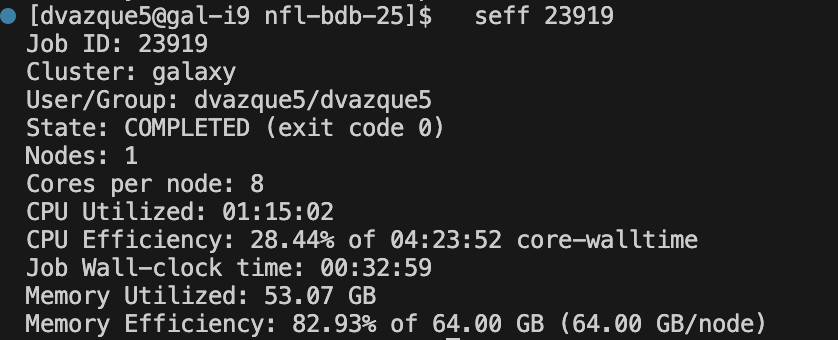

### Q2 Results

**Coverage reader** (1 vs. 2 high safeties)

| Plays | Accuracy |
|---|---|
| Undisguised plays | **93.4%** |
| Disguised plays | **21.1%** |

As expected thse  match Q1's since I only changed the Disguise Score model. 

**Disguise Score model**

| Metric | Value |
|---|---|
| AUC | 0.867 |
| Overall accuracy | 78.1% |
| Accuracy on undisguised plays | 76.2% |
| Accuracy on disguised plays | 80.6% |
| Best cutoff (sensitivity / specificity) | 0.545 (0.751 / 0.840) |
| Best validation accuracy, by fold | 0.768, 0.760, 0.793, 0.776, 0.729 |




| ROC curve (Q2) | Calibration (Q2) |
|---|---|
| 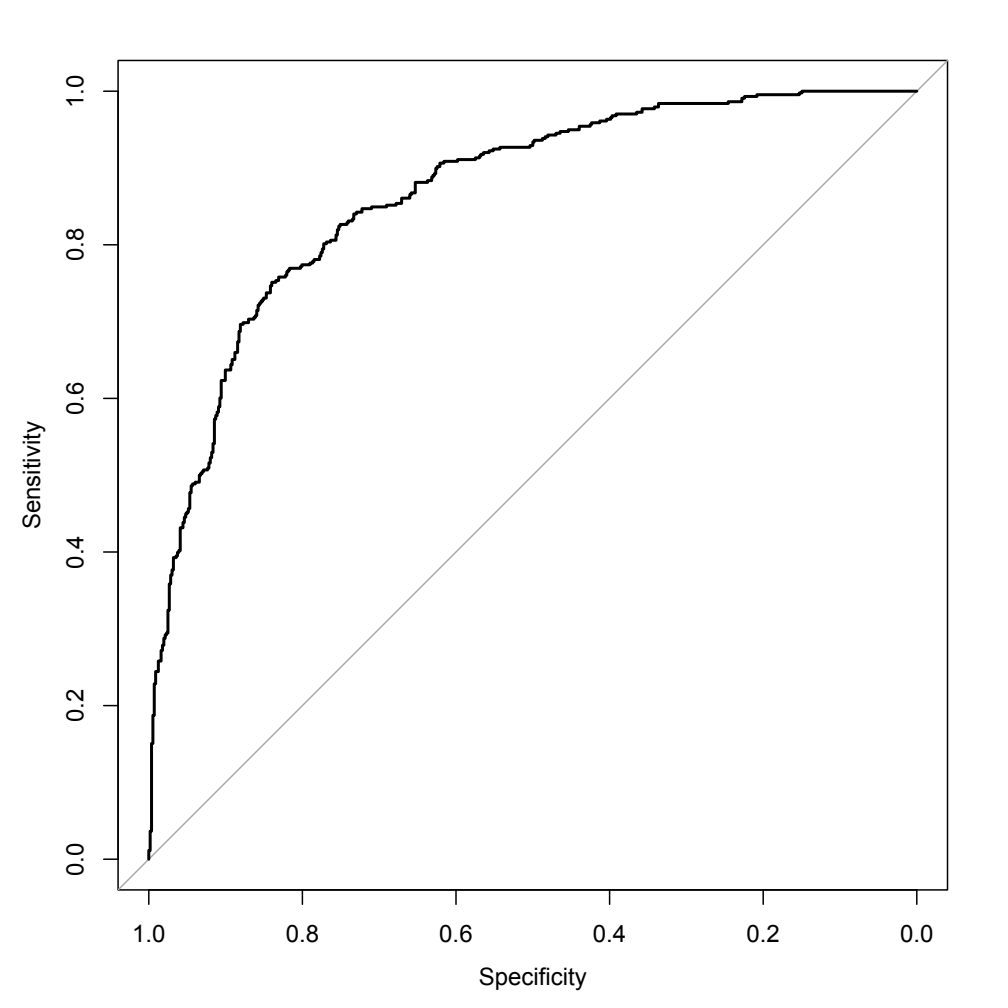 | 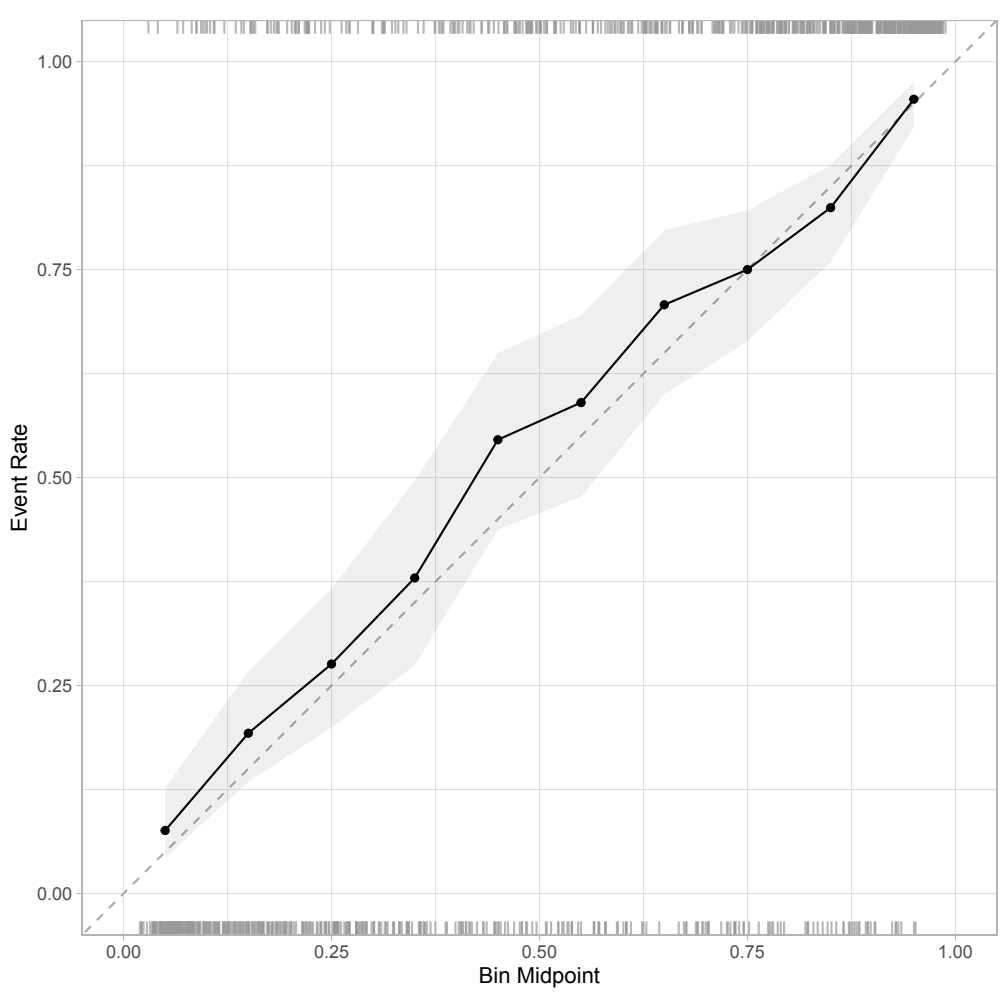 |

### Q2 Training Log

**Disguise Score model** (training loss / validation loss, printed every 10 epochs)

| Epoch | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|
| 10 | 0.597 / 0.600 | 0.578 / 0.571 | 0.613 / 0.582 | 0.583 / 0.602 | 0.571 / 0.593 |
| 20 | 0.529 / 0.576 | 0.533 / 0.536 | 0.549 / 0.529 | 0.529 / 0.552 | 0.521 / 0.602 |
| 30 | 0.484 / 0.533 | 0.472 / 0.558 | 0.491 / 0.540 | 0.476 / 0.526 | 0.448 / 0.562 |
| 40 | 0.429 / 0.512 | 0.419 / 0.528 | 0.444 / 0.482 | 0.423 / 0.522 | 0.387 / 0.641 |
| 50 | 0.375 / 0.556 | 0.358 / 0.538 | 0.387 / 0.510 | 0.367 / 0.499 | 0.332 / 0.687 |

Similar to Q1, training loss falls steadily in every fold, while validation loss rises between epochs 40 and 50 in folds 1, 3 and 5. Fold 5 overfits the most: its validation loss climbs from 0.562 at epoch 30 to 0.687 at epoch 50.

### Q2 Mean Disguise Score by Coverage Type

| Coverage | Disguised plays | Undisguised plays | Difference (pts) | Q1 difference (pts) |
|---|---|---|---|---|
| Cover-1 | 76.4% | 21.4% | 55.0 | 55.7 |
| Cover-3 | 71.2% | 23.1% | 48.1 | 48.7 |
| 2-Man | 71.0% | 29.9% | 41.1 | 35.5 |
| Quarters | 69.9% | 37.5% | 32.5 | 29.6 |
| Cover-6 | 62.7% | 33.4% | 29.3 | 27.1 |
| Cover-2 | 62.8% | 34.7% | 28.1 | 23.0 |
| Cover-0 | 78.1% | – | – | – |

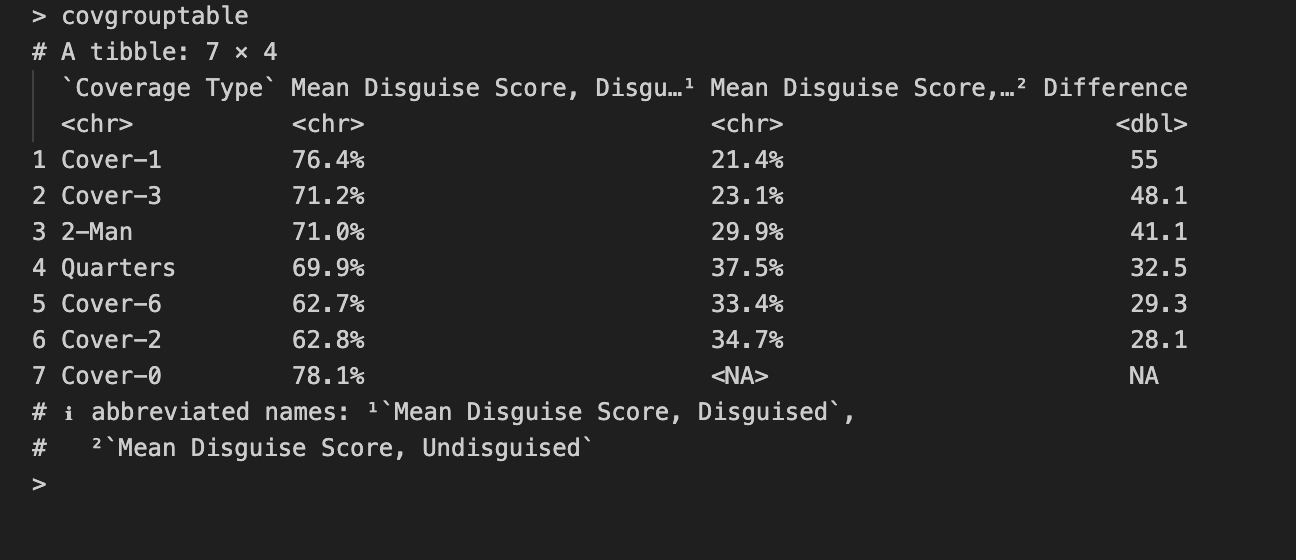

### Q1 vs. Q2 Comparison

**Disguise Score model, Q1 vs. Q2**

| Metric | Q1 (dropout 0.3) | Q2 (dropout 0.5) |
|---|---|---|
| AUC | 0.865 | 0.867 |
| Overall accuracy | 77.7% | 78.1% |
| Accuracy on undisguised plays | 76.5% | 76.2% |
| Accuracy on disguised plays | 79.2% | 80.6% |
| Best cutoff (sensitivity / specificity) | 0.549 (0.740 / 0.838) | 0.545 (0.751 / 0.840) |
| Best validation accuracy, by fold | 0.779, 0.767, 0.783, 0.771, 0.730 | 0.768, 0.760, 0.793, 0.776, 0.729 |

**Training vs. validation loss at epoch 50** (average over the 5 folds)

| | Q1 (dropout 0.3) | Q2 (dropout 0.5) |
|---|---|---|
| Training loss | 0.347 | 0.364 |
| Validation loss | 0.547 | 0.558 |
| Gap | 0.200 | 0.194 |

### How the Results Changed

- **Training got harder.** At 22 of the 25 checkpoints (5 folds × epochs 10–50), training loss was a little higher with dropout 0.5 than with 0.3. For example, in fold 1 it was 0.484 vs. 0.460 at epoch 30 and 0.375 vs. 0.348 at epoch 50. With more neurons switched off, the model fits the training plays more slowly.
- **Overfitting barely changed.** In both runs, training loss falls steadily from epoch 10 to 50, while validation loss mostly levels off after epoch 30 and rises from epoch 40 to 50 in three folds (folds 1, 2 and 5 in Q1; folds 1, 3 and 5 in Q2). Fold 5 is the worst in both runs, with validation loss at 0.633 (Q1) and 0.687 (Q2) by epoch 50. The average gap at epoch 50 only went from 0.200 to 0.194, and validation loss went up a little (0.547 &rarr; 0.558), so dropout 0.5 didn't help the model generalize better.
- **Test results moved only slightly.** AUC went from 0.865 to 0.867 and overall accuracy from 77.7% to 78.1%. Accuracy on disguised plays went up (79.2% &rarr; 80.6%), while accuracy on undisguised plays dropped a little (76.5% &rarr; 76.2%). These changes are small enough that they don't show a real improvement.
- **Two-high coverages separated a bit better.** The disguised vs. undisguised gap grew for 2-Man, Quarters, Cover-6 and Cover-2, while Cover-1 and Cover-3 stayed about the same. The ranking of coverages didn't change.

**Conclusion:** Raising dropout from 0.3 to 0.5 didn't meaningfully change the model. Pollack's 0.3 was a reasonable choice. Her code already saves the model from the epoch with the best validation accuracy, which limits the damage from overfitting. Stopping training earlier around epoch 30–40, where validation loss levels off would target the overfitting more directly than more dropout.